In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import data

plt.rcParams['figure.dpi'] = 120
plt.rcParams['savefig.bbox'] = 'tight'
sns.set_theme(style='whitegrid', palette='muted')
pd.set_option('display.max_columns', 40)
pd.set_option('display.width', 140)
pd.set_option('display.float_format', lambda x: f'{x:,.2f}')

df_raw = data.read_raw()
print(f"Dataset loaded: {df_raw.shape[0]:,} rows x {df_raw.shape[1]} columns")
print(df_raw.head(5).to_string())

ModuleNotFoundError: No module named 'seaborn'

In [ ]:
info_df = pd.DataFrame({
    'dtype': df_raw.dtypes.astype(str),
    'non_null': df_raw.notnull().sum(),
    'null_count': df_raw.isnull().sum(),
    'null_pct': (df_raw.isnull().mean() * 100).round(2),
    'n_unique': df_raw.nunique()
})
print("=== Column Schema & Missingness ===")
print(info_df.to_string())

print("\n=== Numerical Summary ===")
print(df_raw.describe().T[['count', 'mean', 'std', 'min', '50%', 'max']].to_string())

print("\n=== Categorical Summary ===")
print(df_raw.describe(include='object').T.to_string())

=== Column Schema & Missingness ===
                                  dtype  non_null  null_count  null_pct  n_unique
hotel                               str    119390           0      0.00         2
is_canceled                       int64    119390           0      0.00         2
lead_time                         int64    119390           0      0.00       479
arrival_date_year                 int64    119390           0      0.00         3
arrival_date_month                  str    119390           0      0.00        12
arrival_date_week_number          int64    119390           0      0.00        53
arrival_date_day_of_month         int64    119390           0      0.00        31
stays_in_weekend_nights           int64    119390           0      0.00        17
stays_in_week_nights              int64    119390           0      0.00        35
adults                            int64    119390           0      0.00        14
children                        float64    119386           4 

C:\Users\krake\AppData\Local\Temp\ipykernel_3276\862843793.py:15: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  print(df_raw.describe(include='object').T.to_string())


#Data Quality & Edge-Case Audit

Key data integrity checks before analysis and modeling:
* **Missing Values:** `company` (`94.3%` null) and `agent` (`13.7%` null) denote direct bookings without an agency/corporate ID; `country` (`488` nulls) and `children` (`4` nulls) are true missing entries.
* **Exact Duplicate Rows:** `31,994` rows (`26.8%`) are exact duplicates across all 32 columns (typical of multi-room group reservations recorded as identical rows).
* **Invalid Guest/Stay Counts & ADR Outliers:** Rows with `0` total guests, negative `adr` (`-6.38`), or extreme `adr` (`5,400.00`).
* **Target Leakage:** `reservation_status` (`Check-Out`, `Canceled`, `No-Show`) and `reservation_status_date` deterministically leak `is_canceled` and must be dropped prior to supervised modeling.

In [ ]:
zero_guests = df_raw[(df_raw['adults'] + df_raw['children'].fillna(0) + df_raw['babies']) == 0]
neg_adr = df_raw[df_raw['adr'] < 0]
zero_adr = df_raw[df_raw['adr'] == 0]
extreme_adr = df_raw[df_raw['adr'] > 1000]
zero_nights = df_raw[(df_raw['stays_in_weekend_nights'] + df_raw['stays_in_week_nights']) == 0]

audit_summary = pd.DataFrame({
    'Check': [
        'Exact duplicate rows (all 32 columns)',
        'Zero total guests (adults + children + babies == 0)',
        'Zero total nights (weekend + week nights == 0)',
        'Negative ADR (adr < 0)',
        'Zero ADR (adr == 0, complimentary/package)',
        'Extreme ADR (adr > 1,000)'
    ],
    'Row Count': [
        df_raw.duplicated().sum(),
        len(zero_guests),
        len(zero_nights),
        len(neg_adr),
        len(zero_adr),
        len(extreme_adr)
    ]
})
audit_summary['Pct (%)'] = (audit_summary['Row Count'] / len(df_raw) * 100).round(3)
print(audit_summary.to_string(index=False))

print("\n=== Target Leakage Check: reservation_status vs is_canceled ===")
print(pd.crosstab(df_raw['reservation_status'], df_raw['is_canceled']).to_string())

                                              Check  Row Count  Pct (%)
              Exact duplicate rows (all 32 columns)      31994    26.80
Zero total guests (adults + children + babies == 0)        180     0.15
     Zero total nights (weekend + week nights == 0)        715     0.60
                             Negative ADR (adr < 0)          1     0.00
         Zero ADR (adr == 0, complimentary/package)       1959     1.64
                          Extreme ADR (adr > 1,000)          1     0.00

=== Target Leakage Check: reservation_status vs is_canceled ===
is_canceled             0      1
reservation_status              
Canceled                0  43017
Check-Out           75166      0
No-Show                 0   1207




We construct a clean analytical dataset `df` by:
1. Imputing `children` (`0`), `country` (`'Unknown'`), `agent` (`0`), and `company` (`0`).
2. Removing `180` invalid zero-guest rows and `2` negative/extreme `adr` rows (`adr < 0` or `adr > 1,000`).
3. Engineering `total_nights`, `total_guests`, `room_type_changed`, and chronologically ordered `arrival_date_month`.

In [ ]:
df = df_raw.copy()

df['children'] = df['children'].fillna(0).astype(int)
df['country'] = df['country'].fillna('Unknown')
df['agent'] = df['agent'].fillna(0).astype(int)
df['company'] = df['company'].fillna(0).astype(int)

df['total_nights'] = df['stays_in_weekend_nights'] + df['stays_in_week_nights']
df['total_guests'] = df['adults'] + df['children'] + df['babies']
df['room_type_changed'] = (df['reserved_room_type'] != df['assigned_room_type']).astype(int)

month_order = [
    'January', 'February', 'March', 'April', 'May', 'June',
    'July', 'August', 'September', 'October', 'November', 'December'
]
df['arrival_date_month'] = pd.Categorical(df['arrival_date_month'], categories=month_order, ordered=True)

initial_len = len(df)
df = df[(df['total_guests'] > 0) & (df['adr'] >= 0) & (df['adr'] <= 1000)].copy()
print(f"Cleaned dataset shape: {df.shape[0]:,} rows x {df.shape[1]} columns (removed {initial_len - len(df):,} invalid/outlier rows)")

Cleaned dataset shape: 119,208 rows x 35 columns (removed 182 invalid/outlier rows)


C:\Users\krake\AppData\Local\Temp\ipykernel_3276\1385114140.py:4: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax.set_xticklabels(['Not Canceled (0)', 'Canceled (1)'])


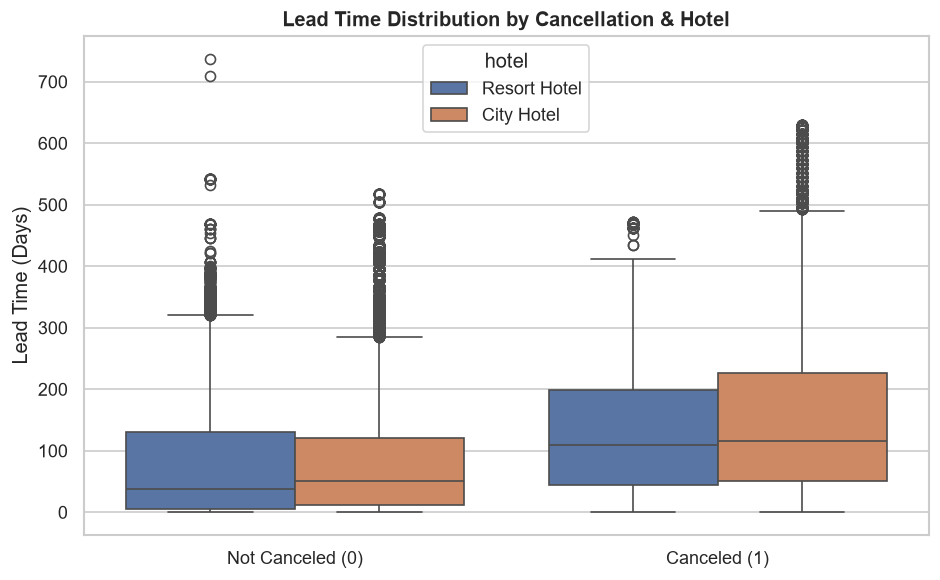

In [ ]:
fig, ax = plt.subplots(figsize=(8, 5))
sns.boxplot(data=df, x='is_canceled', y='lead_time', hue='hotel', ax=ax, palette=['#4C72B0', '#DD8452'])
ax.set_title('Lead Time Distribution by Cancellation & Hotel', fontsize=12, fontweight='bold')
ax.set_xticklabels(['Not Canceled (0)', 'Canceled (1)'])
ax.set_xlabel('')
ax.set_ylabel('Lead Time (Days)')

plt.tight_layout()
plt.show()

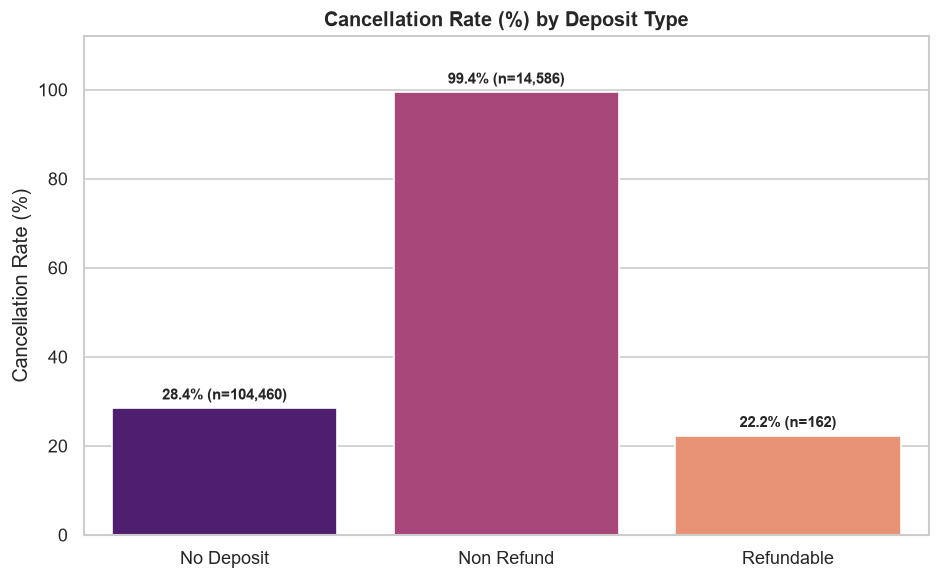

In [ ]:
dep_stats = (
    df.groupby('deposit_type')['is_canceled']
    .agg(bookings='count', cancel_rate='mean')
    .reset_index()
)
dep_stats['cancel_pct'] = dep_stats['cancel_rate'] * 100

fig, ax = plt.subplots(figsize=(8, 5))
sns.barplot(data=dep_stats, x='deposit_type', y='cancel_pct', ax=ax, palette='magma')
ax.set_title('Cancellation Rate (%) by Deposit Type', fontsize=12, fontweight='bold')
ax.set_xlabel('')
ax.set_ylabel('Cancellation Rate (%)')
ax.set_ylim(0, 112)

for i, row in dep_stats.iterrows():
    ax.text(i, row['cancel_pct'] + 2.0, f"{row['cancel_pct']:.1f}% (n={int(row['bookings']):,})", ha='center', fontsize=9, fontweight='bold')

plt.tight_layout()
plt.show()

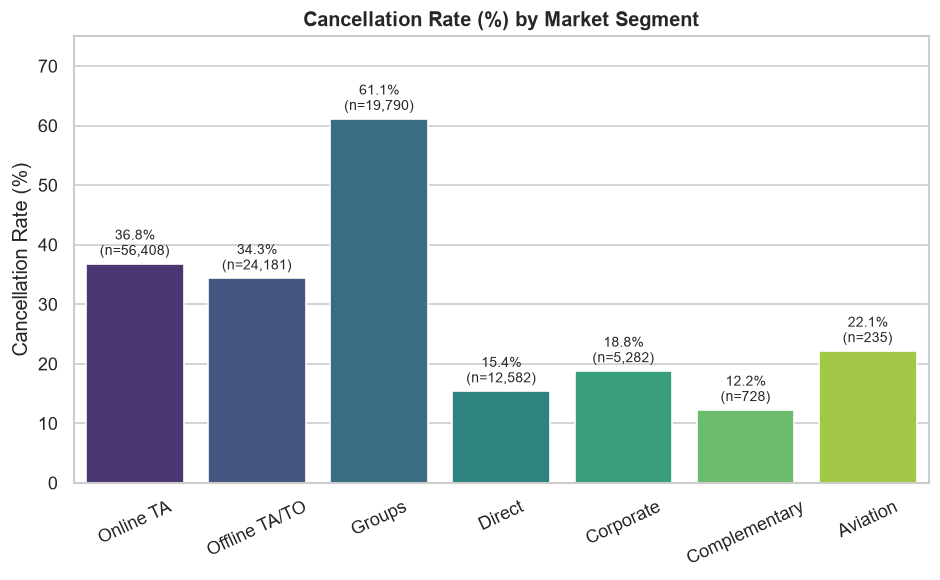

In [ ]:
seg_stats = (
    df[df['market_segment'] != 'Undefined']
    .groupby('market_segment')['is_canceled']
    .agg(bookings='count', cancel_rate='mean')
    .sort_values('bookings', ascending=False)
    .reset_index()
)
seg_stats['cancel_pct'] = seg_stats['cancel_rate'] * 100

fig, ax = plt.subplots(figsize=(8, 5))
sns.barplot(data=seg_stats, x='market_segment', y='cancel_pct', ax=ax, palette='viridis')
ax.set_title('Cancellation Rate (%) by Market Segment', fontsize=12, fontweight='bold')
ax.set_xlabel('')
ax.set_ylabel('Cancellation Rate (%)')
ax.tick_params(axis='x', rotation=25)
ax.set_ylim(0, 75)

for i, row in seg_stats.iterrows():
    ax.text(i, row['cancel_pct'] + 1.5, f"{row['cancel_pct']:.1f}%\n(n={int(row['bookings']):,})", ha='center', fontsize=8.5)

plt.tight_layout()
plt.show()

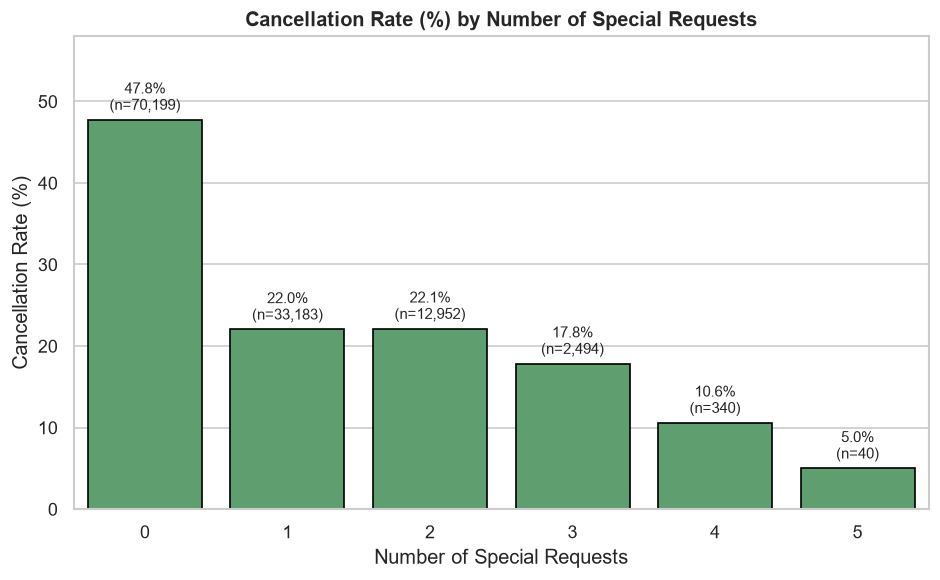

In [ ]:
sns.set_theme(style='whitegrid', palette='muted')

df = pd.read_csv('hotels.csv')
df['children'] = df['children'].fillna(0).astype(int)
df['total_guests'] = df['adults'] + df['children'] + df['babies']
df = df[(df['total_guests'] > 0) & (df['adr'] >= 0) & (df['adr'] <= 1000)].copy()

req_stats = (
    df.groupby('total_of_special_requests')['is_canceled']
    .agg(bookings='count', cancel_rate='mean')
    .reset_index()
)
req_stats['cancel_pct'] = req_stats['cancel_rate'] * 100

fig, ax = plt.subplots(figsize=(8, 5))
sns.barplot(
    data=req_stats,
    x='total_of_special_requests',
    y='cancel_pct',
    ax=ax,
    color='#55A868',
    edgecolor='black'
)

ax.set_title('Cancellation Rate (%) by Number of Special Requests', fontsize=12, fontweight='bold')
ax.set_xlabel('Number of Special Requests')
ax.set_ylabel('Cancellation Rate (%)')
ax.set_ylim(0, 58)

for i, row in req_stats.iterrows():
    ax.text(
        i,
        row['cancel_pct'] + 1.2,
        f"{row['cancel_pct']:.1f}%\n(n={int(row['bookings']):,})",
        ha='center',
        fontsize=9
    )

plt.tight_layout()
plt.show()